In [6]:
import pandas as pd
from pathlib import Path
import numpy as np

In [8]:

data_dir = Path('../data')
df = pd.read_csv('clean.csv')

df.head()

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType,AskPrice,Brand_avgPrice,Model_avgPrice
0,honda,city,23,98000,0,0,Petrol,195000,5.055770e+05,535442.743640
1,toyota,innova,15,190000,0,0,Diesel,375000,1.738645e+06,835954.760274
2,volkswagen,ventotest,14,77246,0,1,Diesel,184999,6.717446e+05,469052.543860
3,maruti suzuki,swift,7,83500,0,0,Diesel,565000,4.790632e+05,473432.824427
4,maruti suzuki,baleno,5,45000,1,1,Petrol,685000,4.790632e+05,616768.929688


In [16]:

import numpy as np, pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error
from catboost import CatBoostRegressor


In [ ]:
df = df.drop(columns=['Brand_avgPrice', 'Model_avgPrice'])

df['km_per_year'] = df['kmDriven'] / df['Age'].clip(lower=1)
df['log_km'] = np.log1p(df['kmDriven'])
df['Brand_model'] = df['Brand'] + ' ' + df['model']

cat_cols = ['Brand', 'model', 'Brand_model', 'FuelType']
 
X = df.drop(columns=['AskPrice'])
y = np.log(df['AskPrice'])
X.head()

,Brand,model,Age,kmDriven,Transmission,Owner,FuelType,km_per_year,log_km,Brand_model
0,honda,city,23,98000,0,0,Petrol,4260.869565,11.492733,honda city
1,toyota,innova,15,190000,0,0,Diesel,12666.666667,12.154785,toyota innova
2,volkswagen,ventotest,14,77246,0,1,Diesel,5517.571429,11.254763,volkswagen ventotest
3,maruti suzuki,swift,7,83500,0,0,Diesel,11928.571429,11.332614,maruti suzuki swift
4,maruti suzuki,baleno,5,45000,1,1,Petrol,9000.000000,10.714440,maruti suzuki baleno


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
catboost_model = CatBoostRegressor(iterations=1500, learning_rate=0.05, depth=7,
                             cat_features=cat_cols, random_seed=42, verbose=0)

model = catboost_model.fit(X_train, y_train)

In [14]:
def report(y_true_log, y_pred_log):
    y_true, y_pred = np.exp(y_true_log), np.exp(y_pred_log)   # back to rupees
    print(f"R2 (rupees)        : {r2_score(y_true, y_pred):.4f}")
    print(f"R2 (log scale)     : {r2_score(y_true_log, y_pred_log):.4f}")
    print(f"MAE                : {mean_absolute_error(y_true, y_pred):,.0f}")
    print(f"MAPE               : {mean_absolute_percentage_error(y_true, y_pred):.3f}")
    print(f"accuracy       : {(1- mean_absolute_percentage_error(y_true, y_pred))*100}")
    print(f"median % error     : {np.median(np.abs(y_pred - y_true) / y_true):.3f}")

report(y_test, model.predict(X_test))

R2 (rupees)        : 0.6906
R2 (log scale)     : 0.8552
MAE                : 246,886
MAPE               : 0.395
accuracy       : 60.50385525097237
median % error     : 0.136


In [21]:
scores = []
for tr, va in KFold(5, shuffle=True, random_state=42).split(X):
    m = model.fit(X.iloc[tr], y.iloc[tr])
    scores.append(r2_score(np.exp(y.iloc[va]), np.exp(m.predict(X.iloc[va]))))

print([round(s, 3) for s in scores], 'mean R2 =', round(np.mean(scores), 4))

[0.691, 0.601, 0.683, 0.43, 0.636] mean R2 = 0.6084


In [19]:
import catboost as cb

# Create a CatBoost Pool containing our training data and categorical feature indices
train_pool = cb.Pool(X_train, y_train, cat_features=cat_cols)

# Define the cross-validation parameters
params = {
    'iterations': 1500,
    'learning_rate': 0.05,
    'depth': 7,
    'loss_function': 'RMSE',
    'random_seed': 42,
    'verbose': 0
}

# Perform cross-validation using CatBoost's native CV
cv_results = cb.cv(
    pool=train_pool,
    params=params,
    fold_count=5,
    shuffle=True,
    partition_random_seed=42,
    verbose=False
)

# Display the final performance metrics
print(f"Best Mean RMSE on CV: {cv_results['test-RMSE-mean'].min():.4f}")
display(cv_results.tail())

Training on fold [0/5]

bestTest = 0.307842179
bestIteration = 1489

Training on fold [1/5]

bestTest = 0.3214911766
bestIteration = 1496

Training on fold [2/5]

bestTest = 0.3377198376
bestIteration = 1487

Training on fold [3/5]

bestTest = 0.333436565
bestIteration = 1478

Training on fold [4/5]

bestTest = 0.302887051
bestIteration = 1448

Best Mean RMSE on CV: 0.3207


,iterations,test-RMSE-mean,test-RMSE-std,train-RMSE-mean,train-RMSE-std
1495,1495,0.320750,0.015281,0.221054,0.003419
1496,1496,0.320761,0.015279,0.220990,0.003406
1497,1497,0.320777,0.015279,0.220934,0.003404
1498,1498,0.320774,0.015276,0.220899,0.003383
1499,1499,0.320778,0.015267,0.220854,0.003379


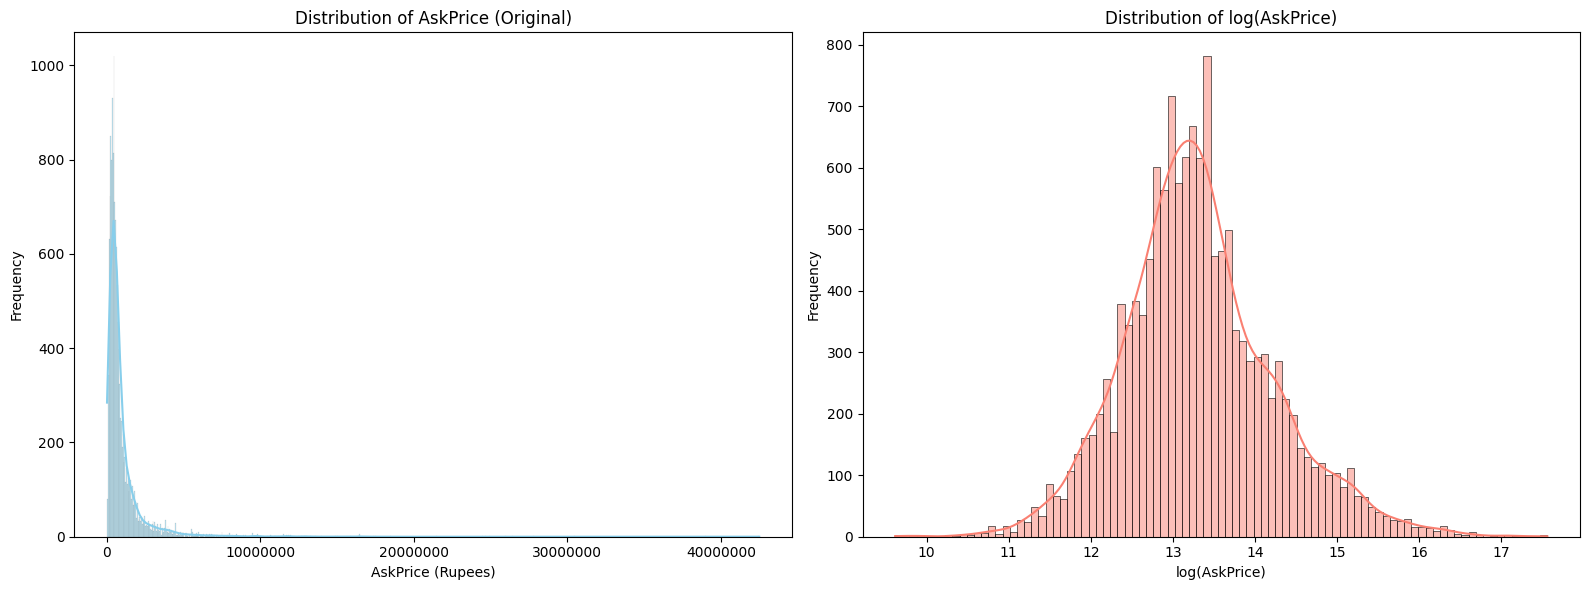

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with two subplots: original and log-transformed AskPrice
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Distribution of original AskPrice
sns.histplot(df['AskPrice'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of AskPrice (Original)')
axes[0].set_xlabel('AskPrice (Rupees)')
axes[0].set_ylabel('Frequency')
axes[0].ticklabel_format(style='plain', axis='x')

# Subplot 2: Distribution of log-transformed AskPrice
sns.histplot(np.log(df['AskPrice']), kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of log(AskPrice)')
axes[1].set_xlabel('log(AskPrice)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()